## 1. Define the Problem

First, identify:

Input: Customer information
Output: Loan default status
Target: Status

## 2. Import Required Libraries

In [5]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier

## 3. Load the Dataset

In [6]:
df = pd.read_csv(r"D:\Brainw\AIML\Machine Learning\Datasets\complex_loan_default_ml_practice.csv")
df.head()

,customer_id,age,annual_income,employment_years,credit_score,debt_to_income,loan_amount,loan_term_months,interest_rate,num_accounts,...,education,marital_status,employment_type,city_tier,has_credit_card,has_mortgage,dependents,bankruptcies,loan_purpose,loan_default
0,CUST_00001,59,156743.0,10.5,604.0,0.292,9426.0,36,9.19,9,...,High School,Single,Salaried,Tier_2,No,Yes,1,1,Vehicle,0
1,CUST_00002,49,134506.0,6.6,635.0,0.374,9841.0,60,13.69,9,...,High School,Widowed,Salaried,Tier_2,No,No,1,2,Education,0
2,CUST_00003,35,186357.0,5.6,710.0,0.113,13721.0,24,12.66,11,...,Bachelor,Single,Contract,Tier_2,Yes,No,1,0,Vehicle,0
3,CUST_00004,63,50393.0,5.2,707.0,0.235,6898.0,60,8.33,5,...,Master,Married,Self-employed,Tier_2,Yes,No,1,0,Personal,0
4,CUST_00005,28,64711.0,NaN,617.0,0.215,46777.0,36,10.14,8,...,High School,Married,Business,Tier_3,Yes,Yes,2,0,Education,0


## 4. Understand the Dataset

### Check rows and columns

In [7]:
print(df.shape)

(5000, 23)


### Check column names

In [8]:
df.columns

Index(['customer_id', 'age', 'annual_income', 'employment_years',
       'credit_score', 'debt_to_income', 'loan_amount', 'loan_term_months',
       'interest_rate', 'num_accounts', 'late_payments', 'open_credit_lines',
       'home_ownership', 'education', 'marital_status', 'employment_type',
       'city_tier', 'has_credit_card', 'has_mortgage', 'dependents',
       'bankruptcies', 'loan_purpose', 'loan_default'],
      dtype='object')

### Check data types

In [9]:
df.dtypes

customer_id           object
age                    int64
annual_income        float64
employment_years     float64
credit_score         float64
debt_to_income       float64
loan_amount          float64
loan_term_months       int64
interest_rate        float64
num_accounts           int64
late_payments          int64
open_credit_lines      int64
home_ownership        object
education             object
marital_status        object
employment_type       object
city_tier             object
has_credit_card       object
has_mortgage          object
dependents             int64
bankruptcies           int64
loan_purpose          object
loan_default           int64
dtype: object

### Get statistical information

In [10]:
df.describe()

,age,annual_income,employment_years,credit_score,debt_to_income,loan_amount,loan_term_months,interest_rate,num_accounts,late_payments,open_credit_lines,dependents,bankruptcies,loan_default
count,5000.00000,4875.000000,4910.000000,4940.000000,4900.000000,4925.000000,5000.000000,4950.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000,5000.00000
mean,43.13460,64093.151385,7.163646,681.756883,0.274688,23091.939695,47.656800,11.160626,6.979800,1.531800,5.01080,1.532800,0.161200,0.19000
std,12.89329,42076.109231,4.585111,74.940904,0.143395,18363.062929,18.141203,2.640572,2.632941,1.379772,2.23358,1.224265,0.399057,0.39234
min,21.00000,18000.000000,0.000000,407.000000,0.010000,2000.000000,12.000000,4.000000,1.000000,0.000000,0.00000,0.000000,0.000000,0.00000
25%,32.00000,37056.500000,3.700000,630.000000,0.162000,11281.000000,36.000000,9.390000,5.000000,1.000000,3.00000,1.000000,0.000000,0.00000
50%,43.00000,54343.000000,7.000000,683.000000,0.260000,18130.000000,48.000000,11.170000,7.000000,1.000000,5.00000,1.000000,0.000000,0.00000
75%,54.00000,79898.000000,10.300000,734.000000,0.370250,28963.000000,60.000000,12.947500,9.000000,2.000000,6.00000,2.000000,0.000000,0.00000
max,65.00000,848088.000000,23.900000,850.000000,0.761000,298595.000000,84.000000,19.840000,18.000000,22.000000,14.00000,7.000000,3.000000,1.00000


### 5. Check Missing Values

In [11]:
df.isnull().sum()

customer_id            0
age                    0
annual_income        125
employment_years      90
credit_score          60
debt_to_income       100
loan_amount           75
loan_term_months       0
interest_rate         50
num_accounts           0
late_payments          0
open_credit_lines      0
home_ownership         0
education             60
marital_status         0
employment_type       75
city_tier              0
has_credit_card        0
has_mortgage           0
dependents             0
bankruptcies           0
loan_purpose           0
loan_default           0
dtype: int64

## 6. Check Duplicate Records

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df = df.drop_duplicates()

### 7. Exploratory Data Analysis — EDA

#### EDA means understanding the dataset before training the model.

In [14]:
print(df["loan_default"].value_counts())

loan_default
0    4050
1     950
Name: count, dtype: int64


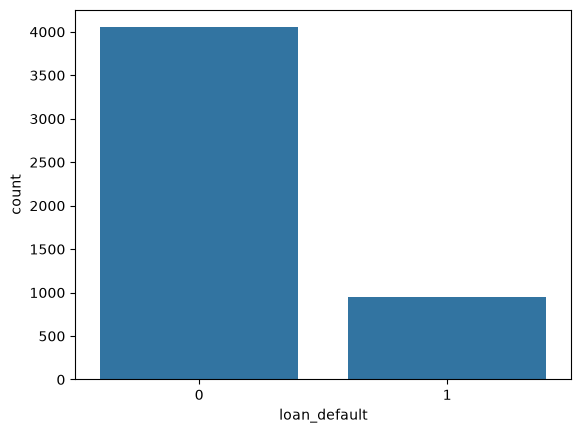

In [15]:
sns.countplot(x="loan_default", data=df)
plt.show()

## 8. Analyze Numerical Features

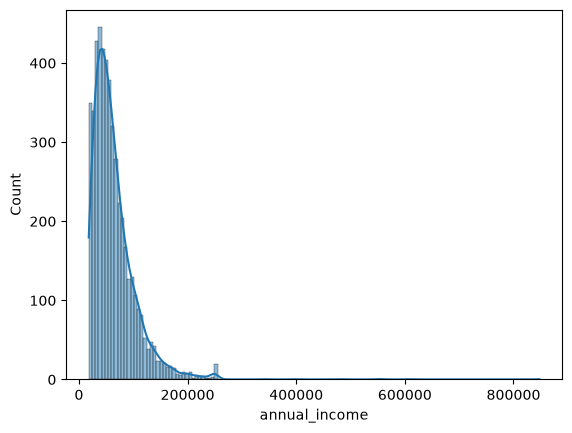

In [16]:
sns.histplot(df["annual_income"], kde=True)
plt.show()

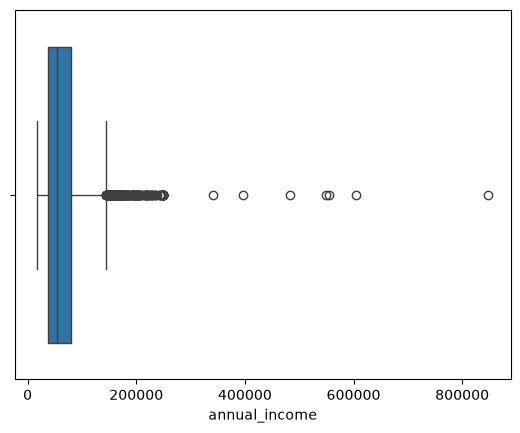

In [17]:
sns.boxplot(x=df["annual_income"])
plt.show()

## 9. Analyze Correlation

In [18]:
correlation = df.corr(numeric_only=True)

print(correlation)

                        age  annual_income  employment_years  credit_score  \
age                1.000000       0.010816          0.014934      0.003193   
annual_income      0.010816       1.000000         -0.021125     -0.002899   
employment_years   0.014934      -0.021125          1.000000      0.023979   
credit_score       0.003193      -0.002899          0.023979      1.000000   
debt_to_income     0.005115       0.010047         -0.008356     -0.016170   
loan_amount        0.012646       0.011619          0.004721      0.004319   
loan_term_months   0.022755       0.017700          0.009754     -0.004325   
interest_rate      0.000831       0.006560          0.005026     -0.310142   
num_accounts      -0.008830      -0.009967         -0.026119     -0.006872   
late_payments      0.001519      -0.013197         -0.027540      0.004573   
open_credit_lines  0.017544       0.015381         -0.021190     -0.027079   
dependents        -0.023186       0.025396         -0.013301    

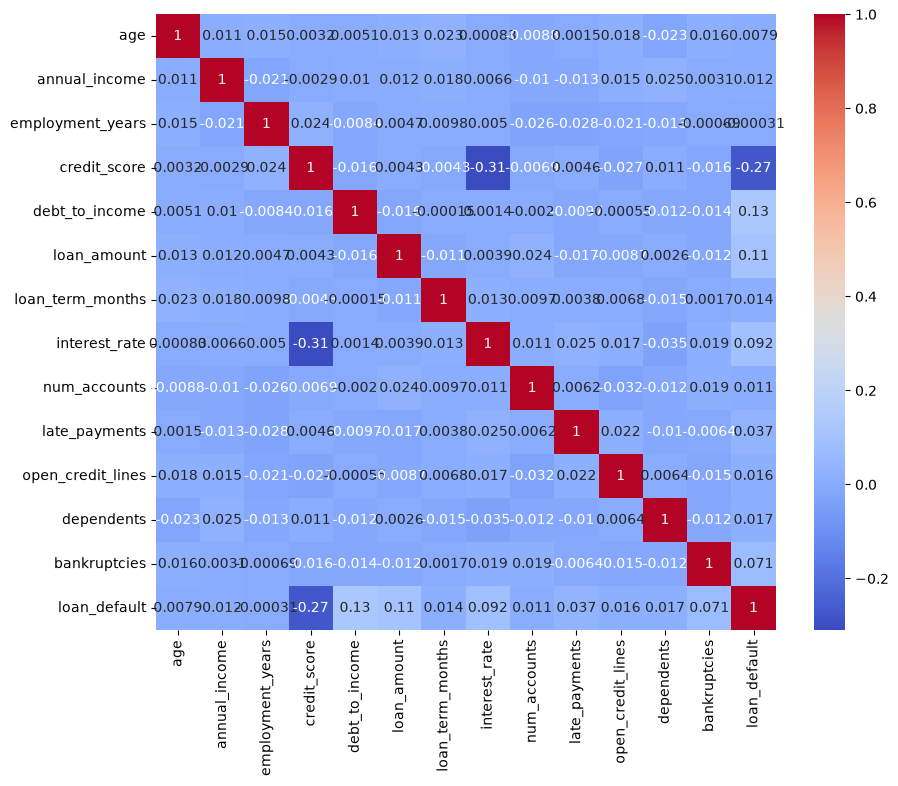

In [ ]:
plt.figure(figsize=(10, 8))

sns.heatmap(correlation,annot=True,cmap="coolwarm")

plt.show()

## 10. Separate Features and Target

In [20]:
X = df.drop(columns=["loan_default"])
y = df["loan_default"]

In [ ]:
X


,customer_id,age,annual_income,employment_years,credit_score,debt_to_income,loan_amount,loan_term_months,interest_rate,num_accounts,...,home_ownership,education,marital_status,employment_type,city_tier,has_credit_card,has_mortgage,dependents,bankruptcies,loan_purpose
0,CUST_00001,59,156743.0,10.5,604.0,0.292,9426.0,36,9.19,9,...,Rent,High School,Single,Salaried,Tier_2,No,Yes,1,1,Vehicle
1,CUST_00002,49,134506.0,6.6,635.0,0.374,9841.0,60,13.69,9,...,Mortgage,High School,Widowed,Salaried,Tier_2,No,No,1,2,Education
2,CUST_00003,35,186357.0,5.6,710.0,0.113,13721.0,24,12.66,11,...,Mortgage,Bachelor,Single,Contract,Tier_2,Yes,No,1,0,Vehicle
3,CUST_00004,63,50393.0,5.2,707.0,0.235,6898.0,60,8.33,5,...,Rent,Master,Married,Self-employed,Tier_2,Yes,No,1,0,Personal
4,CUST_00005,28,64711.0,NaN,617.0,0.215,46777.0,36,10.14,8,...,Mortgage,High School,Married,Business,Tier_3,Yes,Yes,2,0,Education
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,CUST_04996,33,82835.0,3.6,664.0,0.335,7933.0,84,12.66,8,...,Mortgage,Diploma,Single,Self-employed,Tier_2,Yes,No,0,0,Medical
4996,CUST_04997,65,78289.0,6.2,673.0,0.484,23903.0,24,9.34,2,...,Mortgage,Master,Married,Salaried,Tier_2,Yes,Yes,1,0,Education
4997,CUST_04998,37,47403.0,13.9,588.0,0.060,49289.0,24,12.14,6,...,Rent,Bachelor,Married,Contract,Tier_1,Yes,No,0,0,Business
4998,CUST_04999,57,61997.0,9.5,708.0,0.101,37824.0,84,10.48,9,...,Mortgage,High School,Single,Salaried,Tier_3,No,Yes,3,0,Personal


In [22]:
y

0       0
1       0
2       0
3       0
4       0
       ..
4995    0
4996    0
4997    1
4998    0
4999    0
Name: loan_default, Length: 5000, dtype: int64

## 11. Identify Numerical and Categorical Features

In [23]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns

## 12. Train-Test Split

#### 80% → Training
#### 20% → Testing

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

## 13. Handle Missing Values

In [ ]:
numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [26]:
df["employment_years"].head()

0    10.5
1     6.6
2     5.6
3     5.2
4     NaN
Name: employment_years, dtype: float64

## 14. Encode Categorical Variables

In [ ]:
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

## 15. Create ColumnTransformer

#### Now combine numerical and categorical preprocessing.

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num",numeric_transformer,numeric_features),
        ("cat",categorical_transformer,categorical_features)
    ]
)

## 16. Choose an Algorithm

## Logistic Regression

In [29]:
model_LR = LogisticRegression(max_iter=1000,class_weight="balanced")

In [30]:
model_RBF = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

In [38]:
from xgboost import XGBClassifier

model_xg = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42
)

model_xg

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


## 17. Create ML Pipeline
#### Instead of preprocessing manually, we can combine preprocessing and model training.

In [39]:
model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model_RBF", RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

## 18. Train the Model

In [40]:
model_pipeline.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('model_RBF', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## 19. Make Predictions

In [41]:
y_pred = model_pipeline.predict(X_test)

## 20. Probability Prediction

In [42]:
y_probability = model_pipeline.predict_proba(X_test)[:, 1]

## 21. Evaluate Accuracy

In [ ]:
accuracy = accuracy_score(y_test,y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.732


## 22. Precision

In [ ]:
precision = precision_score(y_test, y_pred)

print("Precision:", precision)

Precision: 0.3401639344262295


## 23. Recall

In [ ]:
recall = recall_score(y_test, y_pred)

print("Recall:", recall)

Recall: 0.4368421052631579


## 24. F1 Score

#### F1 balances precision and recall.

In [46]:
f1 = f1_score(
    y_test,
    y_pred
)

print("F1 Score:", f1)

F1 Score: 0.3824884792626728


## 25. ROC-AUC

In [47]:
roc_auc = roc_auc_score(
    y_test,
    y_probability
)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.7125536062378168


## 26. Classification Report

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.80      0.83       810
           1       0.34      0.44      0.38       190

    accuracy                           0.73      1000
   macro avg       0.60      0.62      0.61      1000
weighted avg       0.76      0.73      0.74      1000



## 27. Confusion Matrix

#### A confusion matrix is extremely important for classification.

In [ ]:
cm = confusion_matrix(y_test,y_pred)

print(cm)

[[649 161]
 [107  83]]


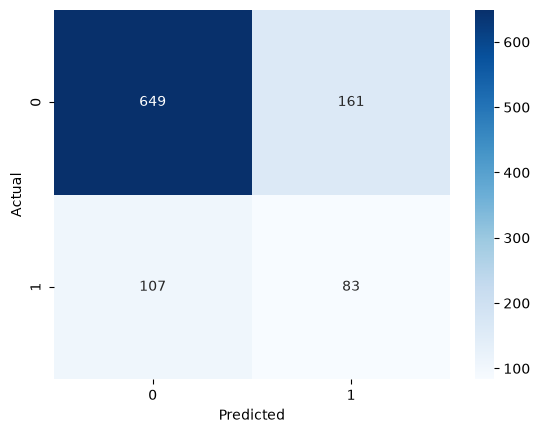

In [50]:
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 28. Compare Multiple Algorithms

In [53]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    
    
    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    )
}

In [54]:
results = []

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),
        "Precision": precision_score(
            y_test,
            predictions
        ),
        "Recall": recall_score(
            y_test,
            predictions
        ),
        "F1": f1_score(
            y_test,
            predictions
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            probabilities
        )
    })

In [55]:
results_df = pd.DataFrame(results)

print(results_df)

                 Model  Accuracy  Precision    Recall        F1   ROC-AUC
0  Logistic Regression     0.743   0.379928  0.557895  0.452026  0.742073
1        Random Forest     0.732   0.340164  0.436842  0.382488  0.712554
2              XGBoost     0.825   0.641509  0.178947  0.279835  0.708057


## 29. Cross-Validation

#### A single train-test split isn't always enough.

In [56]:
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score

In [57]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [58]:
scores = cross_val_score(
    model_pipeline,
    X,
    y,
    cv=cv,
    scoring="f1"
)

print(scores)
print("Mean F1:", scores.mean())

[0.38287154 0.34328358 0.38497653 0.39012346 0.3963964 ]
Mean F1: 0.3795302995243196


## 30. Hyperparameter Tuning

#### Once you choose an algorithm, tune its parameters.

In [62]:
# For Random Forest:

from sklearn.model_selection import GridSearchCV

param_grid = {
    "model_RBF__n_estimators": [100, 200],
    "model_RBF__max_depth": [5, 10],
    "model_RBF__min_samples_split": [2, 5]
}


In [63]:
grid_search = GridSearchCV(
    model_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

In [ ]:
grid_search.fit(X_train,y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model_RBF__max_depth': [5, 10], 'model_RBF__min_samples_split': [2, 5], 'model_RBF__n_estimators': [100, 200]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [65]:
print(grid_search.best_params_)

{'model_RBF__max_depth': 5, 'model_RBF__min_samples_split': 5, 'model_RBF__n_estimators': 100}


In [66]:
print(grid_search.best_score_)

0.38443739050894604


In [67]:
best_model = grid_search.best_estimator_

## 31. Evaluate the Tuned Model

In [ ]:
y_pred = best_model.predict(X_test)

y_probability = best_model.predict_proba(X_test)[:, 1]

In [69]:
print(
    "Accuracy:",
    accuracy_score(y_test, y_pred)
)

print(
    "Precision:",
    precision_score(y_test, y_pred)
)

print(
    "Recall:",
    recall_score(y_test, y_pred)
)

print(
    "F1:",
    f1_score(y_test, y_pred)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_probability)
)

Accuracy: 0.711
Precision: 0.3250883392226148
Recall: 0.4842105263157895
F1: 0.3890063424947146
ROC-AUC: 0.7004873294346978


## 32. Save the Model

In [71]:
import os
import joblib

# Create the folder if it does not exist
os.makedirs("models", exist_ok=True)

# Save your model
joblib.dump(best_model, "models/baseline_rf_model.joblib")

['models/baseline_rf_model.joblib']

In [ ]:
model = joblib.load("models/baseline_rf_model.joblib")

## 33. Make Prediction on New Data

In [79]:
new_customer = pd.DataFrame({
    "customer_id": [10001],
    "age": [35],
    "annual_income": [60000],
    "credit_score": [720],
    "employment_years": [8],
    "employment_type": ["Salaried"],
    "marital_status": ["Married"],
    "dependents": [2],
    "education": ["Graduate"],
    "city_tier": ["Tier 1"],
    "loan_amount": [250000],
    "loan_term_months": [60],
    "interest_rate": [8.5],
    "debt_to_income": [0.30],
    "has_credit_card": [1],
    "has_mortgage": [0],
    "late_payments": [1],
    "open_credit_lines": [4],
    "num_accounts": [6],
    "bankruptcies": [0],
    "home_ownership": ["Own"],
    "loan_purpose": ["Home"]
})



In [80]:
prediction = model.predict(new_customer)

print(prediction)

[1]


In [ ]:
probability = model.predict_proba(new_customer)

print(probability)

[[0.4939971 0.5060029]]


## 34. Deploy Through Flask

In [ ]:
from flask import Flask, request, jsonify
import joblib

app = Flask(__name__)

model = joblib.load("models/baseline_rf_model.joblib")


@app.route("/predict", methods=["POST"])
def predict():

    data = request.get_json()

    input_data = pd.DataFrame([data])

    prediction = model.predict(input_data)[0]

    probability = model.predict_proba(input_data)[0, 1]

    return jsonify({
        "prediction": int(prediction),
        "probability": float(probability)
    })


if __name__ == "__main__":
    app.run(
        host="0.0.0.0",
        port=5000
    )

 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5000
 * Running on http://10.120.30.177:5000
Press CTRL+C to quit


### The API flow becomes:

Client
  ↓
POST /predict
  ↓
JSON Data
  ↓
Flask
  ↓
Saved ML Pipeline
  ↓
Prediction
  ↓
JSON Response

## 35. Complete ML Workflow

#### You should remember this sequence for interviews and projects:

                 CSV Dataset
                      |
                      ↓
              Data Understanding
                      |
                      ↓
                    EDA
                      |
          ┌───────────┴───────────┐
          ↓                       ↓
     Numerical                Categorical
          ↓                       ↓
     Missing Values          Missing Values
          ↓                       ↓
       Scaling                 Encoding
          └───────────┬───────────┘
                      ↓
                Feature Engineering
                      ↓
                Feature Selection
                      ↓
               Train/Test Split
                      ↓
             ┌────────┴─────────┐
             ↓                  ↓
       Multiple Models      Cross Validation
             ↓                  ↓
             └────────┬─────────┘
                      ↓
              Hyperparameter Tuning
                      ↓
                 Best Model
                      ↓
              Model Evaluation
                      ↓
                Save Model
                      ↓
                 Prediction API

1. Problem Definition
        ↓
2. Data Collection
        ↓
3. Data Understanding
        ↓
4. EDA
        ↓
5. Data Cleaning
        ↓
6. Feature Engineering
        ↓
7. Feature Selection
        ↓
8. Train-Test Split
        ↓
9. Preprocessing
        ↓
10. Algorithm Selection
        ↓
11. Model Training
        ↓
12. Prediction
        ↓
13. Model Evaluation
        ↓
14. Cross Validation
        ↓
15. Hyperparameter Tuning
        ↓
16. Model Comparison
        ↓
17. Final Model
        ↓
18. Model Saving
        ↓
19. API / Deployment
        ↓
20. Monitoring & Retraining

"I first performed EDA and preprocessing, 
split the data using stratification, 
trained multiple classification models,
evaluated them using precision, recall, F1-score and ROC-AUC,
performed cross-validation and hyperparameter tuning, and
selected the final model based on the business objective."